# <u><b>Exploratory Data Analysis (EDA) & Visualization</b></u>

## <b style='color: yellow;'>0.</b> <u>Import Libraries</u>

In [7]:
import csv
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configurations
sns.set_style('whitegrid')
warnings.filterwarnings('ignore')
pd.set_option('display.width', 1000)                # Keeps lines from wrapping.
pd.set_option('display.max_columns', None)          # Displays every single column.
plt.rcParams['figure.figsize'] = (10, 5)

DATA_PATH = './excel/final_dataset_main.xlsx'

In [8]:
df = pd.read_excel(DATA_PATH)
df['Sales Order Date'] = pd.to_datetime(df['Sales Order Date'])
print(df.shape)
df.head()

(265070, 134)


,So Internal Id,Sales Order Date,Sales Order Number,Customer Internal Id,Item Internal Id,Item Code,Base Price,Quantity,List Price,Year,Month,Quarter,is_month_end,is_quarter_end,Day of Week,is_weekend,Day of Month,Total Sales Amount,Discount Amount,Discount Percentage,Total Gross Value,Total Discount Value,Unit Selling Price,Customer Cumulative Revenue,Customer Order Count,Customer AOV,Customer Total LTV,is_discounted,is_zero_base_price,Days Since Last Purchase,Product-Level Demand,Item Price Elasticity Ratio,Customer Unique Item Count,Customer Total Unique Items Overall,sin_month,cos_month,Quantity_Capped,Total Sales Amount_Capped,Base Price_Capped,Days_Since_Last_Sale,Sales_Frequency_Ratio_Units,Sales_Frequency_Ratio_Orders,Order_Size_Tier_Encoded,Inventory_Risk_Tier_Encoded,Customer_Order_Frequency,Item_Order_Frequency,Customer Type_VIP,Production Status_Discontinue,Production Status_To Be Advised,Sales Order Status Group_Loss,Sales Order Status Group_On going,Product Category 1_Geared Motor,Product Category 1_HMI,Product Category 1_INV,Product Category 1_LVS,Product Category 1_MEATH,Product Category 1_MEE,Product Category 1_MELIPC,Product Category 1_PLC,Product Category 1_Robot,Product Category 1_SC,Product Category 1_SV,Product Category 1_Scada,Product Category 1_Software,Product Category 1_Tension Controller,Product Category 1_iQSS,Fa Sub Industries_Agriculture / Farming,Fa Sub Industries_Automation,Fa Sub Industries_Automobile,Fa Sub Industries_Automobile Parts,Fa Sub Industries_Biotechnology,Fa Sub Industries_Built in Equipment,Fa Sub Industries_Chemicals,Fa Sub Industries_Consumer Product,Fa Sub Industries_Corporate,Fa Sub Industries_Design Office,Fa Sub Industries_Developer,Fa Sub Industries_Education,Fa Sub Industries_Electronic Parts,Fa Sub Industries_Electronics,Fa Sub Industries_Energy,Fa Sub Industries_Engineering,Fa Sub Industries_Equipment Trading Company,Fa Sub Industries_Factory/Warehouse,Fa Sub Industries_Food & Beverage,Fa Sub Industries_Foods(Food and Packaging Machinery),Fa Sub Industries_General Contractor,Fa Sub Industries_General Machinery,Fa Sub Industries_Glass,Fa Sub Industries_Government,Fa Sub Industries_Healthcare,Fa Sub Industries_Healthcare and Pharmaceuticals,Fa Sub Industries_Household Equipment Parts,Fa Sub Industries_Household and Personal Care,Fa Sub Industries_IT & Software,Fa Sub Industries_Industrial Building,Fa Sub Industries_Industrial Machinery,Fa Sub Industries_Information SI,Fa Sub Industries_Instrumentation SI,Fa Sub Industries_Lithium Ion Battery,Fa Sub Industries_M&E Contractor,Fa Sub Industries_Machine,Fa Sub Industries_Medical Devices,Fa Sub Industries_Medical/Medicine Machinery,Fa Sub Industries_Metal,Fa Sub Industries_Motorcycle,Fa Sub Industries_Other,Fa Sub Industries_Packaging,Fa Sub Industries_Paper,Fa Sub Industries_Petroleum,Fa Sub Industries_Pharmaceutical/Medical Engineering,Fa Sub Industries_Pharmaceuticals,Fa Sub Industries_Plastics,Fa Sub Industries_Power company,Fa Sub Industries_Printed Circuit Board,Fa Sub Industries_Real Estate and Construction,Fa Sub Industries_Residental Market,Fa Sub Industries_Robotic,Fa Sub Industries_Rubber,Fa Sub Industries_Semiconductor,Fa Sub Industries_Software Vendor,Fa Sub Industries_Solar Cell,Fa Sub Industries_Steel(Including Steel SI),Fa Sub Industries_Subcontractor,"Fa Sub Industries_Synthetic Resin,Rubber",Fa Sub Industries_Telecommunications,Fa Sub Industries_Textile,Fa Sub Industries_Tooling Machinery,Fa Sub Industries_Trading Company,Fa Sub Industries_Transportation and Storage,Fa Sub Industries_Transportation/Transport Machinery,Fa Sub Industries_Water Treatment and Utilities,Fa Sub Industries_Wholesale and Distribution,Fa Sub Industries_Wood
0,8149886,2022-12-01,DDRW,702,57209,ICD,16103.0,1,16103.0,2022,12,4,False,False,3,False,1,16103.0,0.0,0.000000,16103.0,0.0,16103.0,16103.0,1,16103.0,46836.0,False,False,0,1.272966,1.099698,1,3,-2.449294e-16,1.000000,1,16103.0,16103.0,392,0.332419,0.261138,3,3,3,381,0,1,0,0,0,0,0,0,0,

# 1. Structural Sanity Check

In [9]:
print(df.info())
print('Duplicate rows:', df.duplicated().sum())
print()
print('Missing Values (top 15):')
print(df.isnull().sum().sort_values(ascending=False).head(15))
print()
print(df.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 265070 entries, 0 to 265069
Columns: 134 entries, So Internal Id to Fa Sub Industries_Wood
dtypes: bool(5), datetime64[us](1), float64(19), int64(107), str(2)
memory usage: 263.9 MB
None
Duplicate rows: 0

Missing Values (top 15):
So Internal Id          0
Sales Order Date        0
Sales Order Number      0
Customer Internal Id    0
Item Internal Id        0
Item Code               0
Base Price              0
Quantity                0
List Price              0
Year                    0
Month                   0
Quarter                 0
is_month_end            0
is_quarter_end          0
Day of Week             0
dtype: int64

                                                       count                        mean                  min                  25%                  50%                  75%                  max            std
So Internal Id                                      265070.0              8285568.262957            7165143.0        

Raw vs Capped outlier Treatment Check<br>
Confirms whether the '_Capped' versions actually reduced the influence of extreme values.

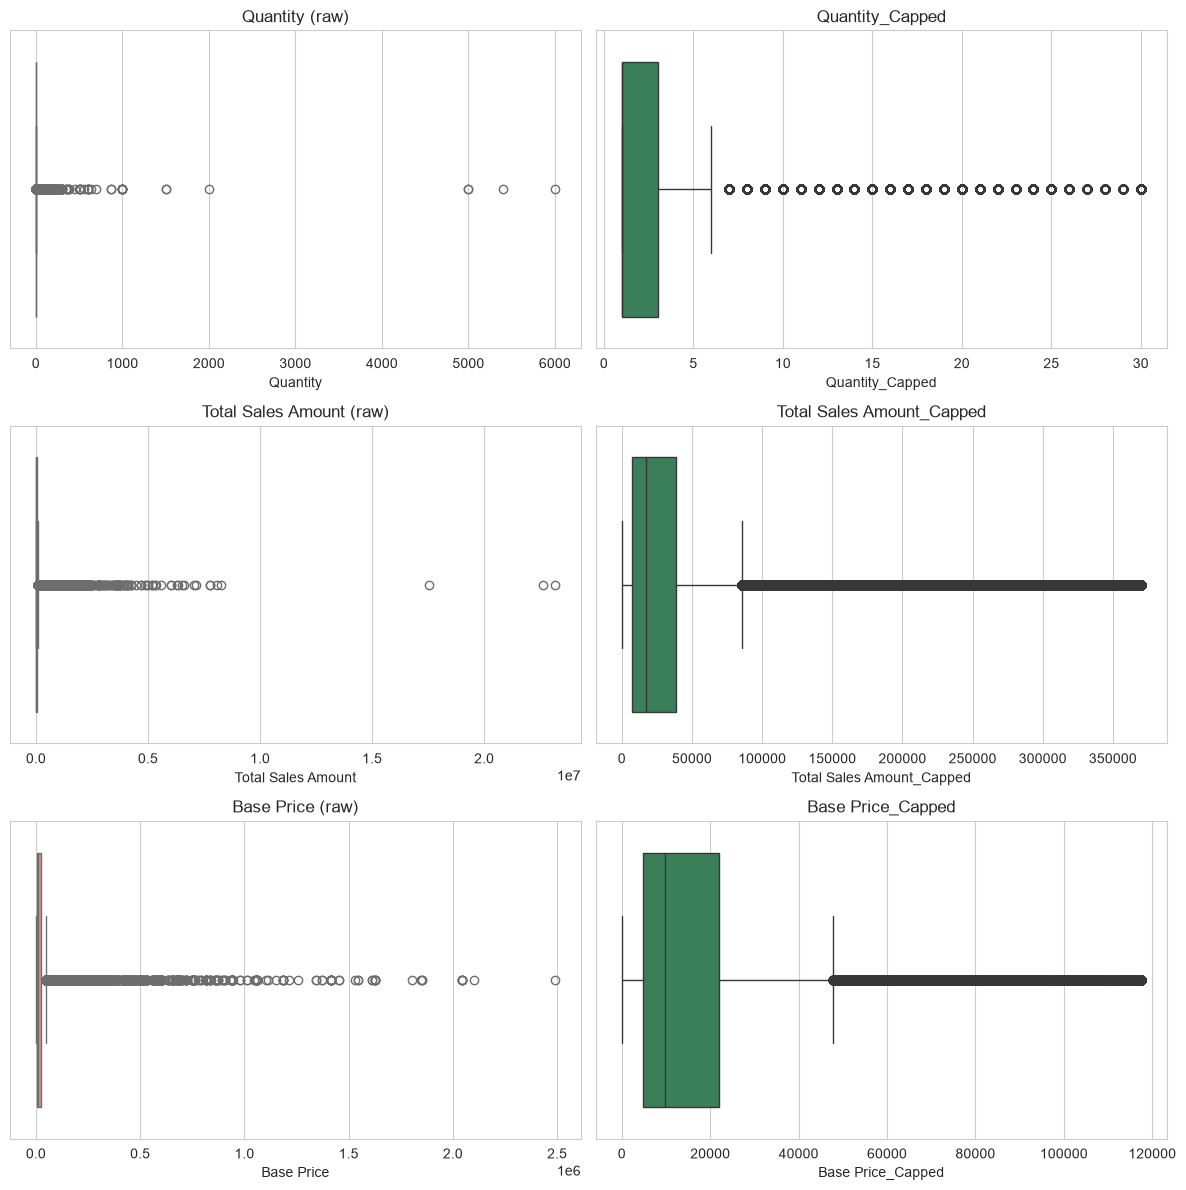

In [10]:
pairs = [
    ('Quantity', 'Quantity_Capped'),
    ('Total Sales Amount', 'Total Sales Amount_Capped'),
    ('Base Price', 'Base Price_Capped'),
]

fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 4 * len(pairs)))
for i, (raw, capped) in enumerate(pairs):
    sns.boxplot(x=df[raw], ax=axes[i, 0], color='salmon')
    axes[i, 0].set_title(f'{raw} (raw)')
    sns.boxplot(x=df[capped], ax=axes[i, 1], color='seagreen')
    axes[i, 1].set_title(f'{capped}')
plt.tight_layout()
plt.show()

# 2. Univariate Distributions

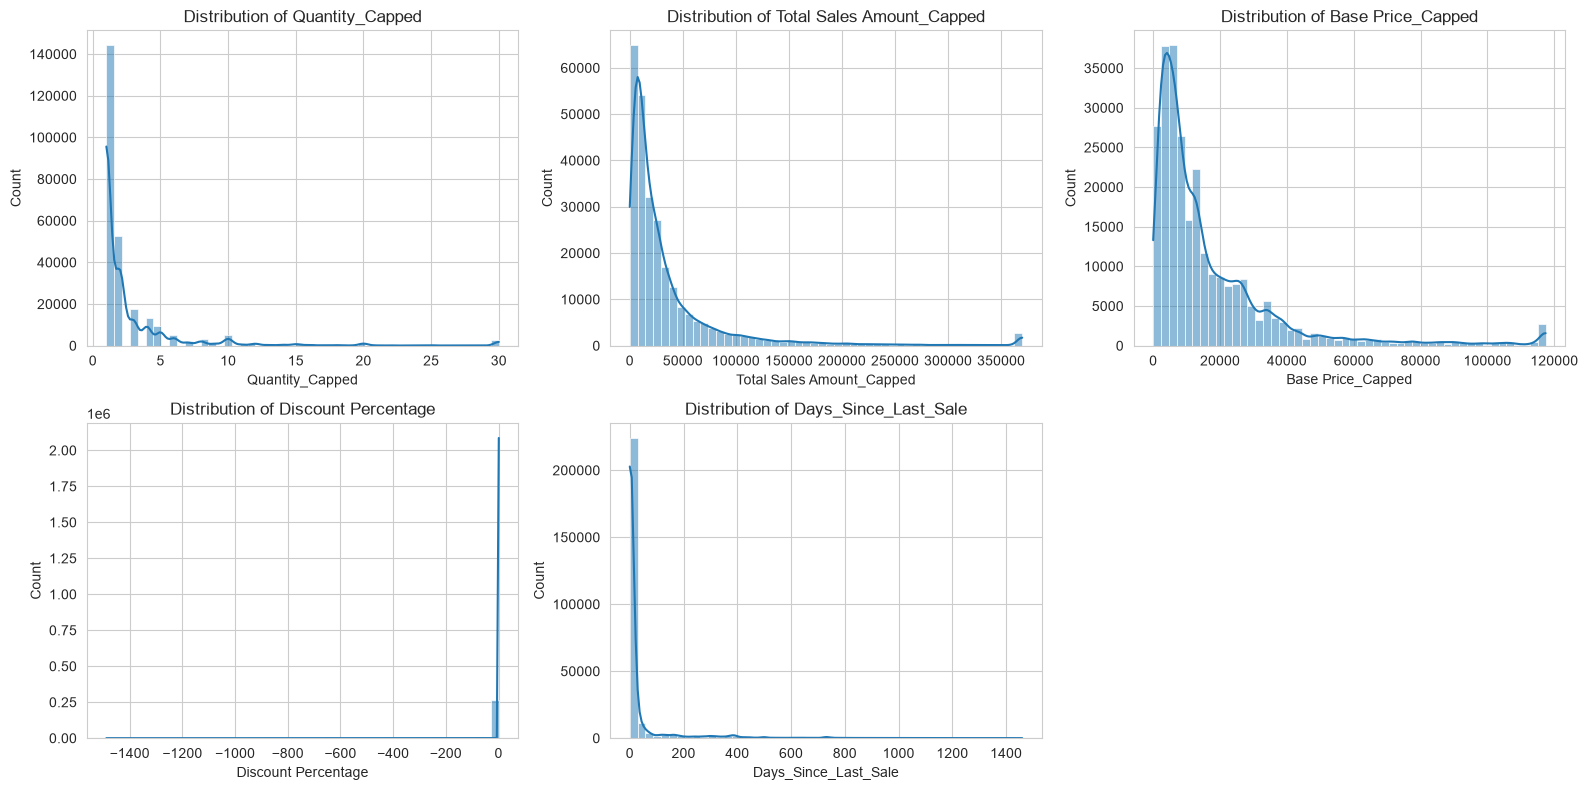

In [11]:
num_cols = ['Quantity_Capped', 'Total Sales Amount_Capped', 'Base Price_Capped',
            'Discount Percentage', 'Days_Since_Last_Sale']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=50, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Decode one-hot columns back to a single categorical
`Product Category 1_*` and `Fa Sub Industries_*` were one-hot encoded for modelling.
For readable bar charts we collapse them back into one column each.

In [12]:
def decode_onehot(frame, prefix):
    cols = [c for c in frame.columns if c.startswith(prefix)]
    sub = frame[cols]
    # rows that are all zero belong to the dropped baseline category
    decoded = sub.idxmax(axis=1).str.replace(prefix, '', regex=False)
    decoded = decoded.where(sub.sum(axis=1) > 0, other='Other/Baseline')
    return decoded

df['Product_Category'] = decode_onehot(df, 'Product Category 1_')
df['Industry'] = decode_onehot(df, 'Fa Sub Industries_')

df['Product_Category'].value_counts()

Product_Category
PLC                   147359
SV                     44749
INV                    32143
HMI                    22091
SC                      4874
MEE                     3912
Software                2043
iQSS                    1859
LVS                     1747
Other/Baseline          1254
Scada                   1156
Robot                    891
Geared Motor             633
MEATH                    178
Tension Controller       177
MELIPC                     4
Name: count, dtype: int64

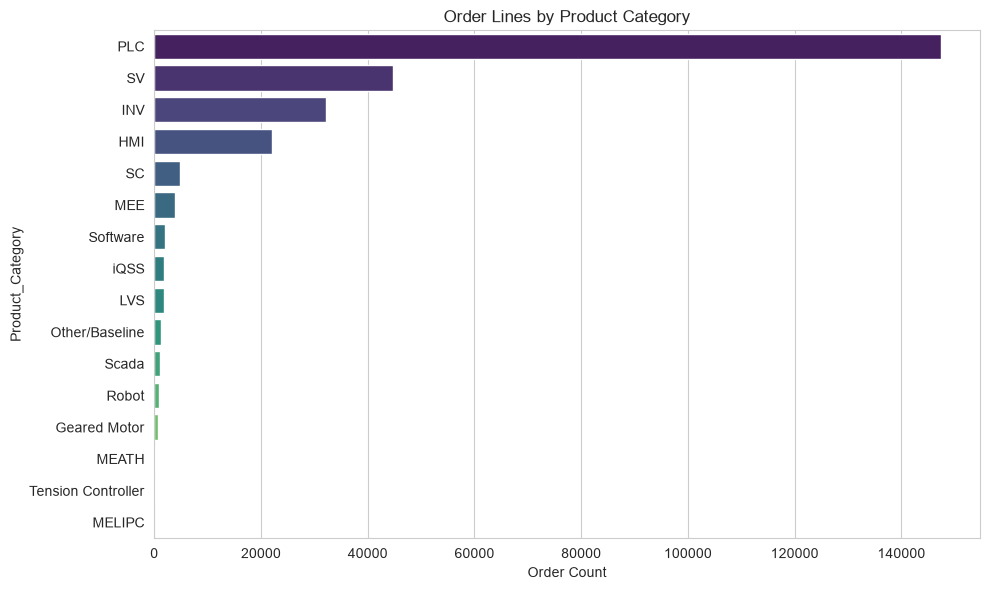

In [13]:
plt.figure(figsize=(10, 6))
order = df['Product_Category'].value_counts().index
sns.countplot(data=df, y='Product_Category', order=order, palette='viridis')
plt.title('Order Lines by Product Category')
plt.xlabel('Order Count')
plt.tight_layout()
plt.show()

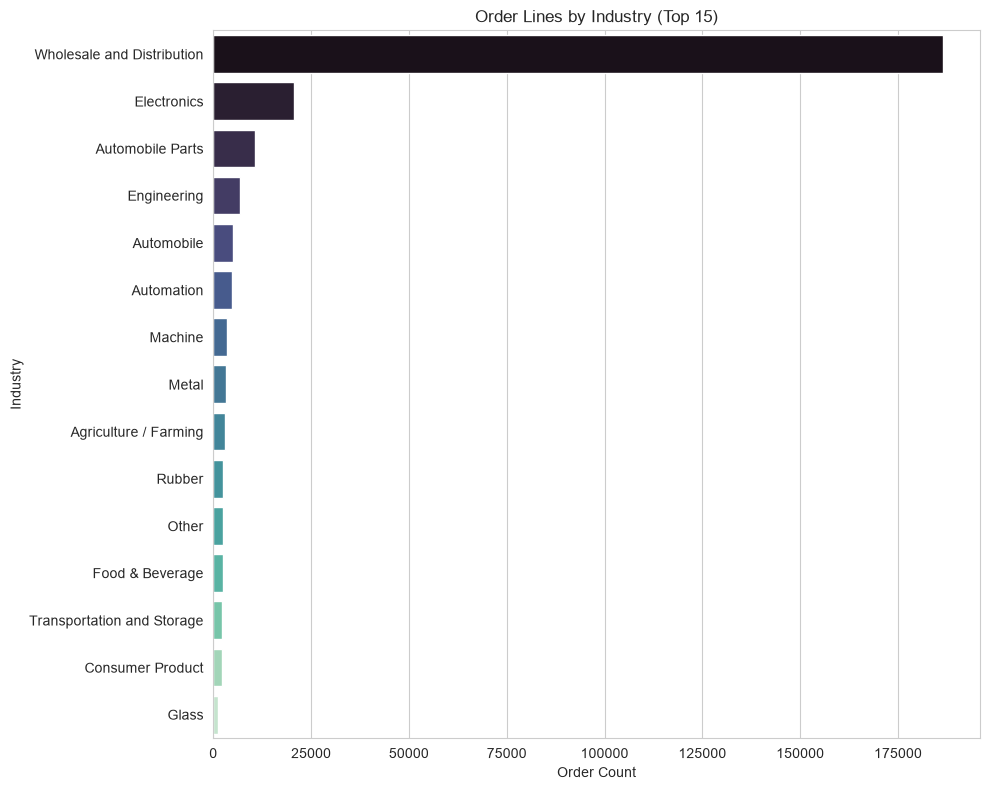

In [14]:
plt.figure(figsize=(10, 8))
top_industries = df['Industry'].value_counts().head(15).index
sns.countplot(data=df[df['Industry'].isin(top_industries)], y='Industry',
              order=top_industries, palette='mako')
plt.title('Order Lines by Industry (Top 15)')
plt.xlabel('Order Count')
plt.tight_layout()
plt.show()

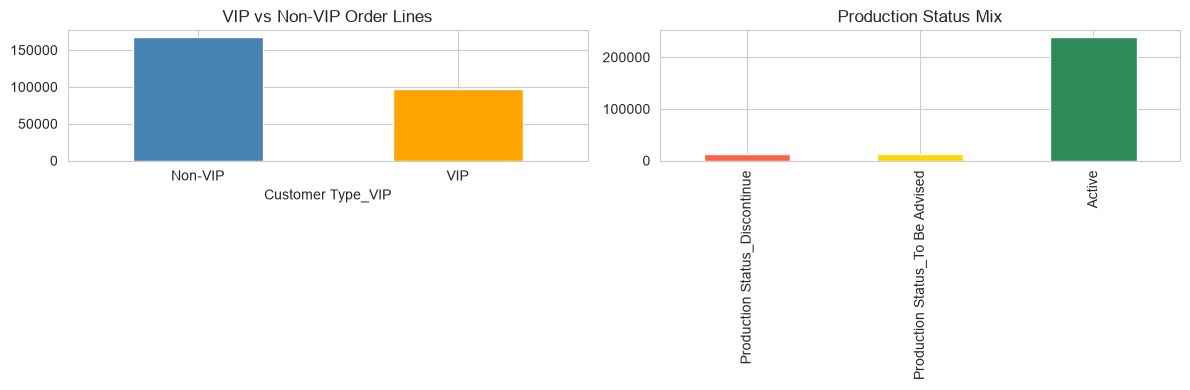

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Customer Type_VIP'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'orange'])
axes[0].set_title('VIP vs Non-VIP Order Lines')
axes[0].set_xticklabels(['Non-VIP', 'VIP'], rotation=0)

status_counts = df[['Production Status_Discontinue', 'Production Status_To Be Advised']].sum()
status_counts['Active'] = len(df) - status_counts.sum()
status_counts.plot(kind='bar', ax=axes[1], color=['tomato', 'gold', 'seagreen'])
axes[1].set_title('Production Status Mix')
plt.tight_layout()
plt.show()

## 3. Time Series & Seasonality (forecasting inputs)

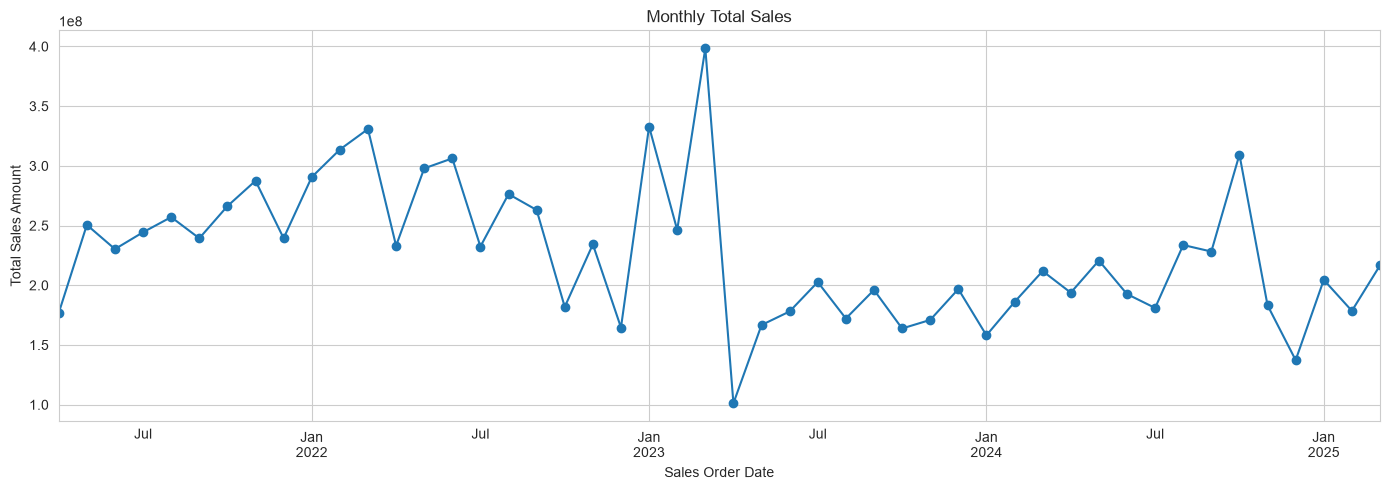

In [16]:
monthly = df.set_index('Sales Order Date').resample('ME')['Total Sales Amount'].sum()

plt.figure(figsize=(14, 5))
monthly.plot(marker='o')
plt.title('Monthly Total Sales')
plt.ylabel('Total Sales Amount')
plt.tight_layout()
plt.show()

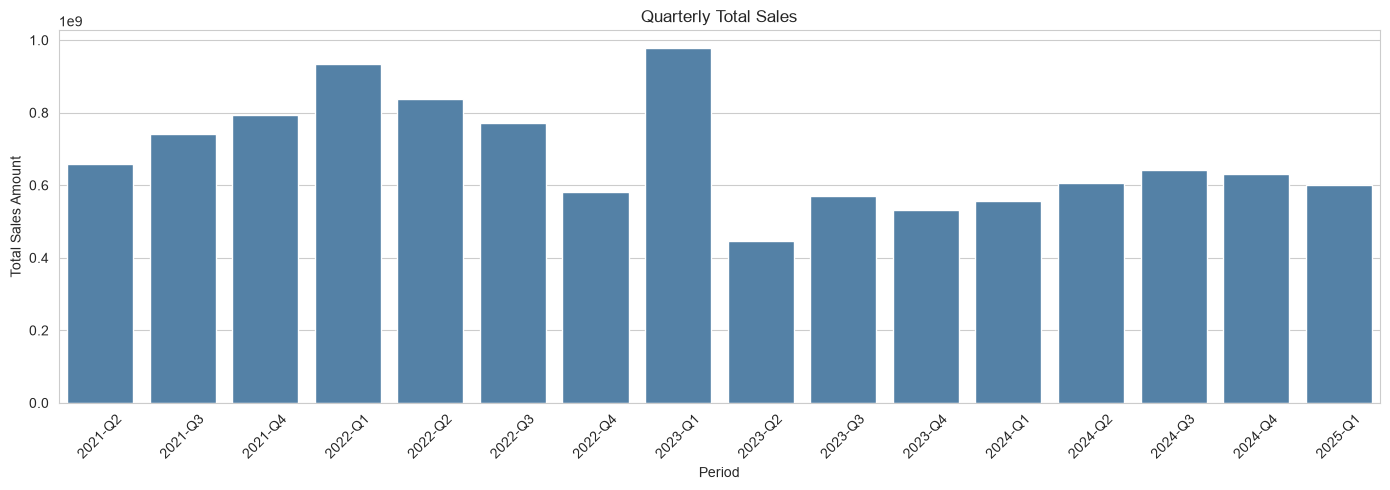

In [17]:
quarterly = df.groupby(['Year', 'Quarter'])['Total Sales Amount'].sum().reset_index()
quarterly['Period'] = quarterly['Year'].astype(str) + '-Q' + quarterly['Quarter'].astype(str)

plt.figure(figsize=(14, 5))
sns.barplot(data=quarterly, x='Period', y='Total Sales Amount', color='steelblue')
plt.xticks(rotation=45)
plt.title('Quarterly Total Sales')
plt.tight_layout()
plt.show()


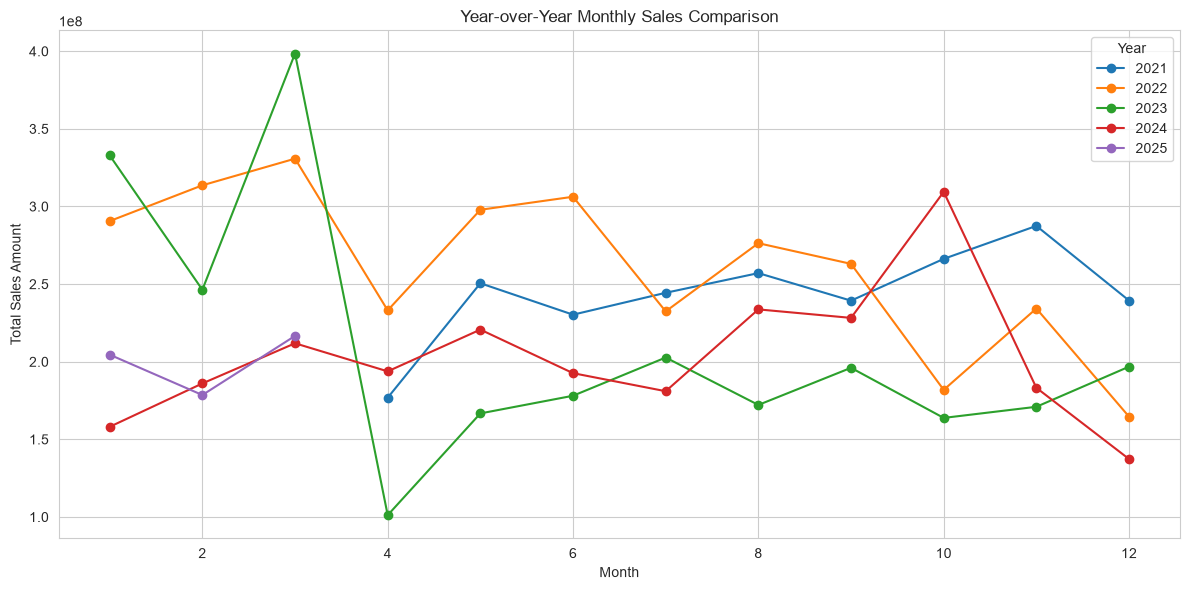

In [18]:
pivot_yoy = df.groupby(['Year', 'Month'])['Total Sales Amount'].sum().unstack(level=0)

plt.figure(figsize=(12, 6))
for year in pivot_yoy.columns:
    plt.plot(pivot_yoy.index, pivot_yoy[year], marker='o', label=str(year))
plt.title('Year-over-Year Monthly Sales Comparison')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')
plt.legend(title='Year')
plt.tight_layout()
plt.show()


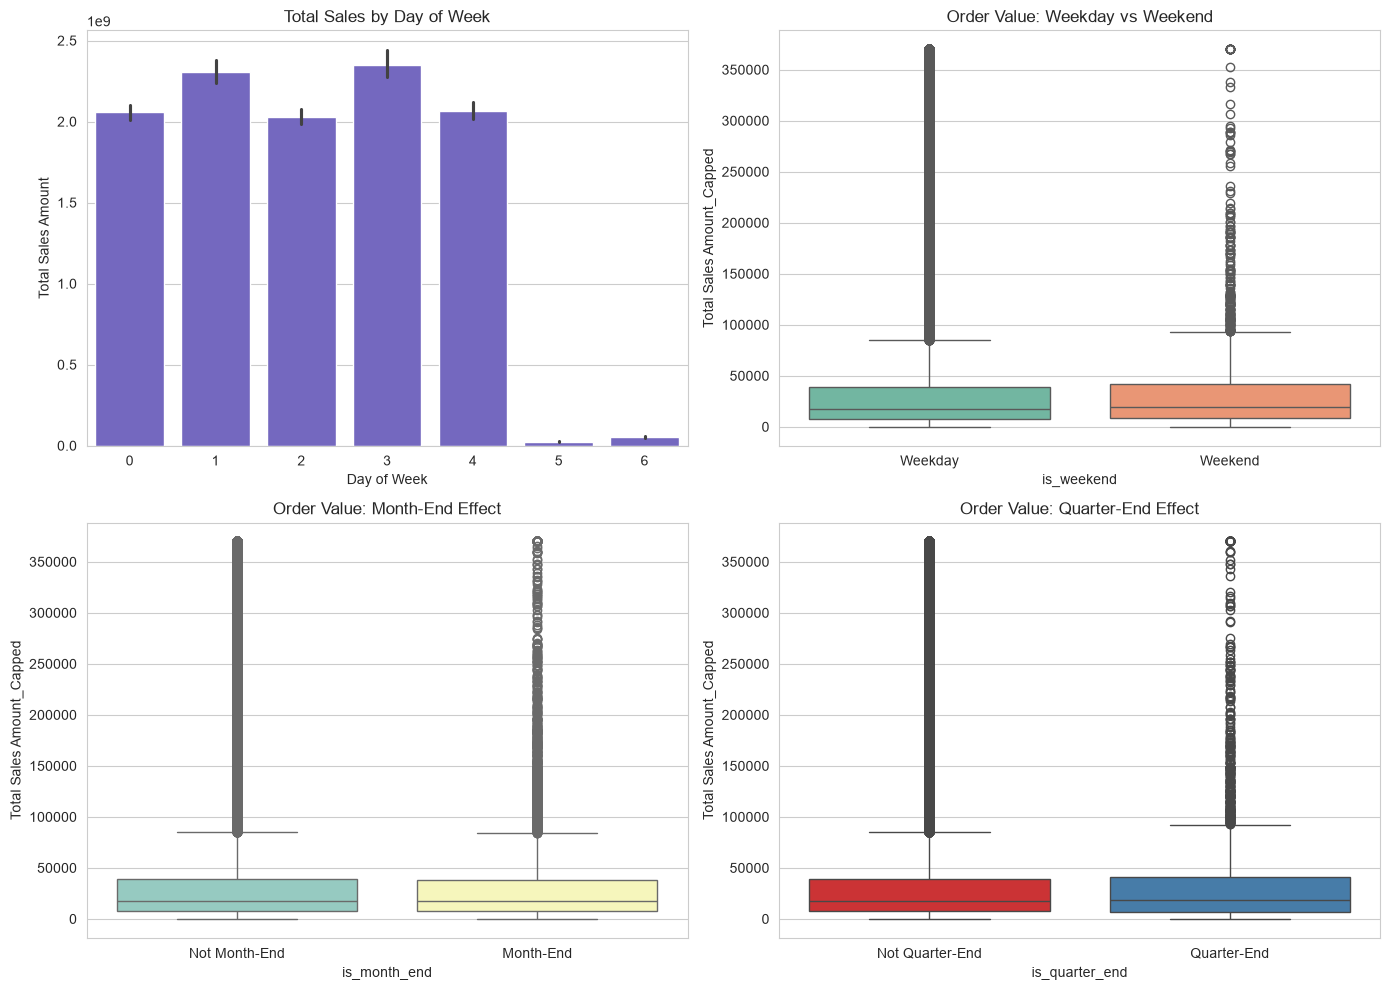

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.barplot(data=df, x='Day of Week', y='Total Sales Amount', estimator=sum, ax=axes[0, 0], color='slateblue')
axes[0, 0].set_title('Total Sales by Day of Week')

sns.boxplot(data=df, x='is_weekend', y='Total Sales Amount_Capped', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Order Value: Weekday vs Weekend')
axes[0, 1].set_xticklabels(['Weekday', 'Weekend'])

sns.boxplot(data=df, x='is_month_end', y='Total Sales Amount_Capped', ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title('Order Value: Month-End Effect')
axes[1, 0].set_xticklabels(['Not Month-End', 'Month-End'])

sns.boxplot(data=df, x='is_quarter_end', y='Total Sales Amount_Capped', ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Order Value: Quarter-End Effect')
axes[1, 1].set_xticklabels(['Not Quarter-End', 'Quarter-End'])

plt.tight_layout()
plt.show()


## 4. Bivariate Relationships

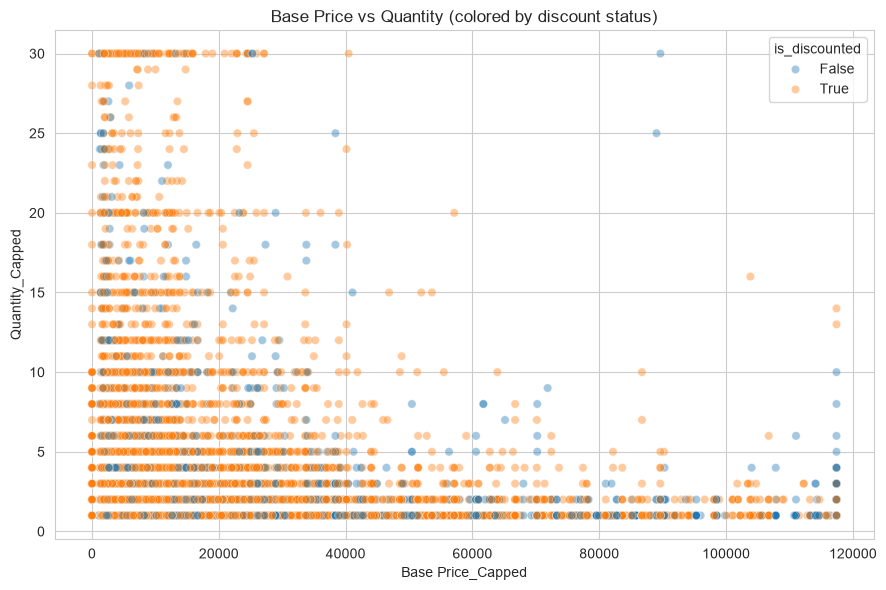

In [20]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df.sample(min(20000, len(df)), random_state=42),
                 x='Base Price_Capped', y='Quantity_Capped', hue='is_discounted', alpha=0.4)
plt.title('Base Price vs Quantity (colored by discount status)')
plt.tight_layout()
plt.show()


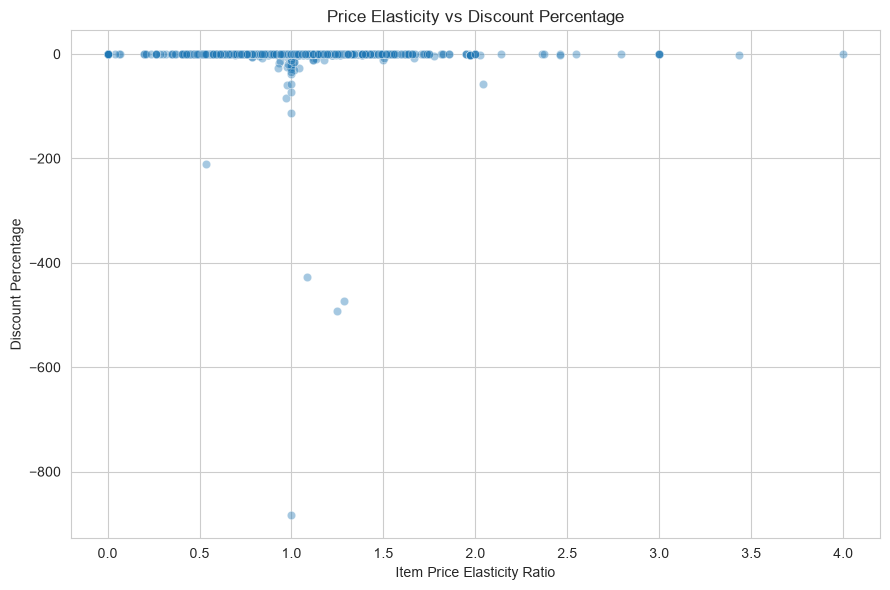

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df.sample(min(20000, len(df)), random_state=42),
                 x='Item Price Elasticity Ratio', y='Discount Percentage', alpha=0.4)
plt.title('Price Elasticity vs Discount Percentage')
plt.tight_layout()
plt.show()


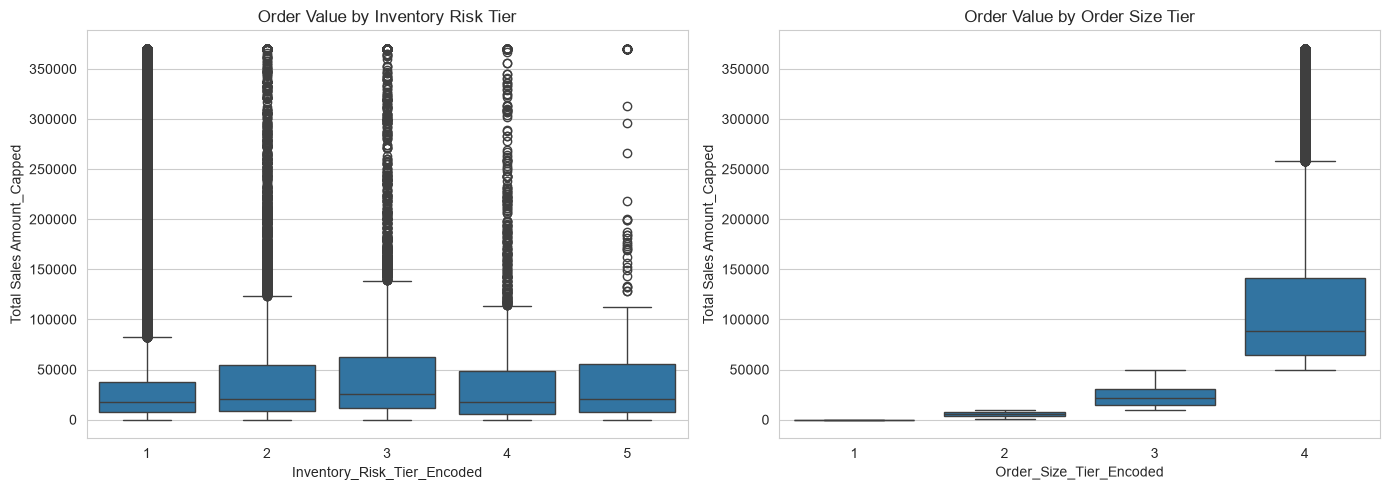

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='Inventory_Risk_Tier_Encoded', y='Total Sales Amount_Capped', ax=axes[0])
axes[0].set_title('Order Value by Inventory Risk Tier')

sns.boxplot(data=df, x='Order_Size_Tier_Encoded', y='Total Sales Amount_Capped', ax=axes[1])
axes[1].set_title('Order Value by Order Size Tier')
plt.tight_layout()
plt.show()


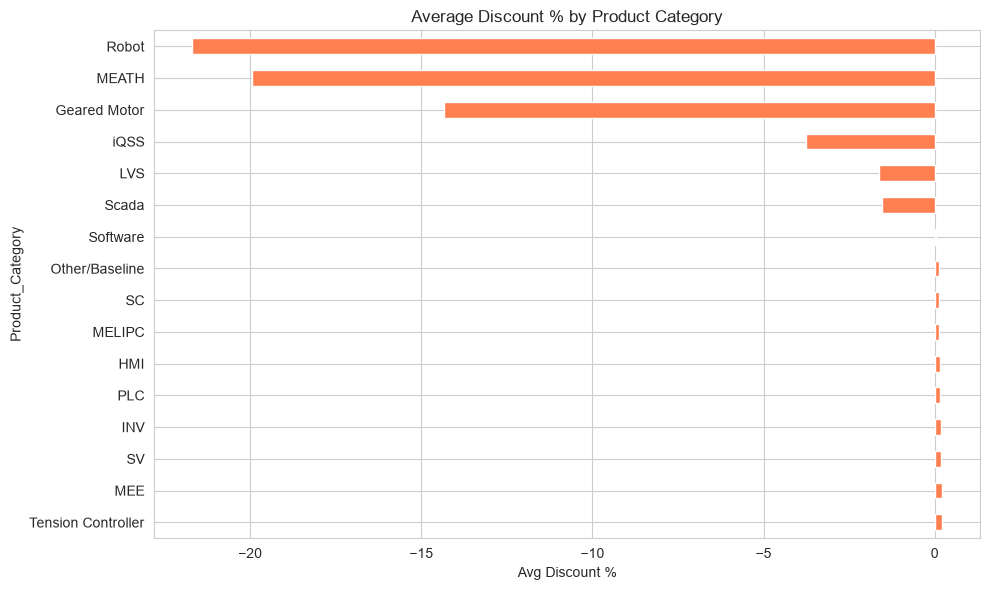

In [23]:
cat_discount = df.groupby('Product_Category')['Discount Percentage'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
cat_discount.plot(kind='barh', color='coral')
plt.title('Average Discount % by Product Category')
plt.xlabel('Avg Discount %')
plt.tight_layout()
plt.show()


## 5. Advanced Plots

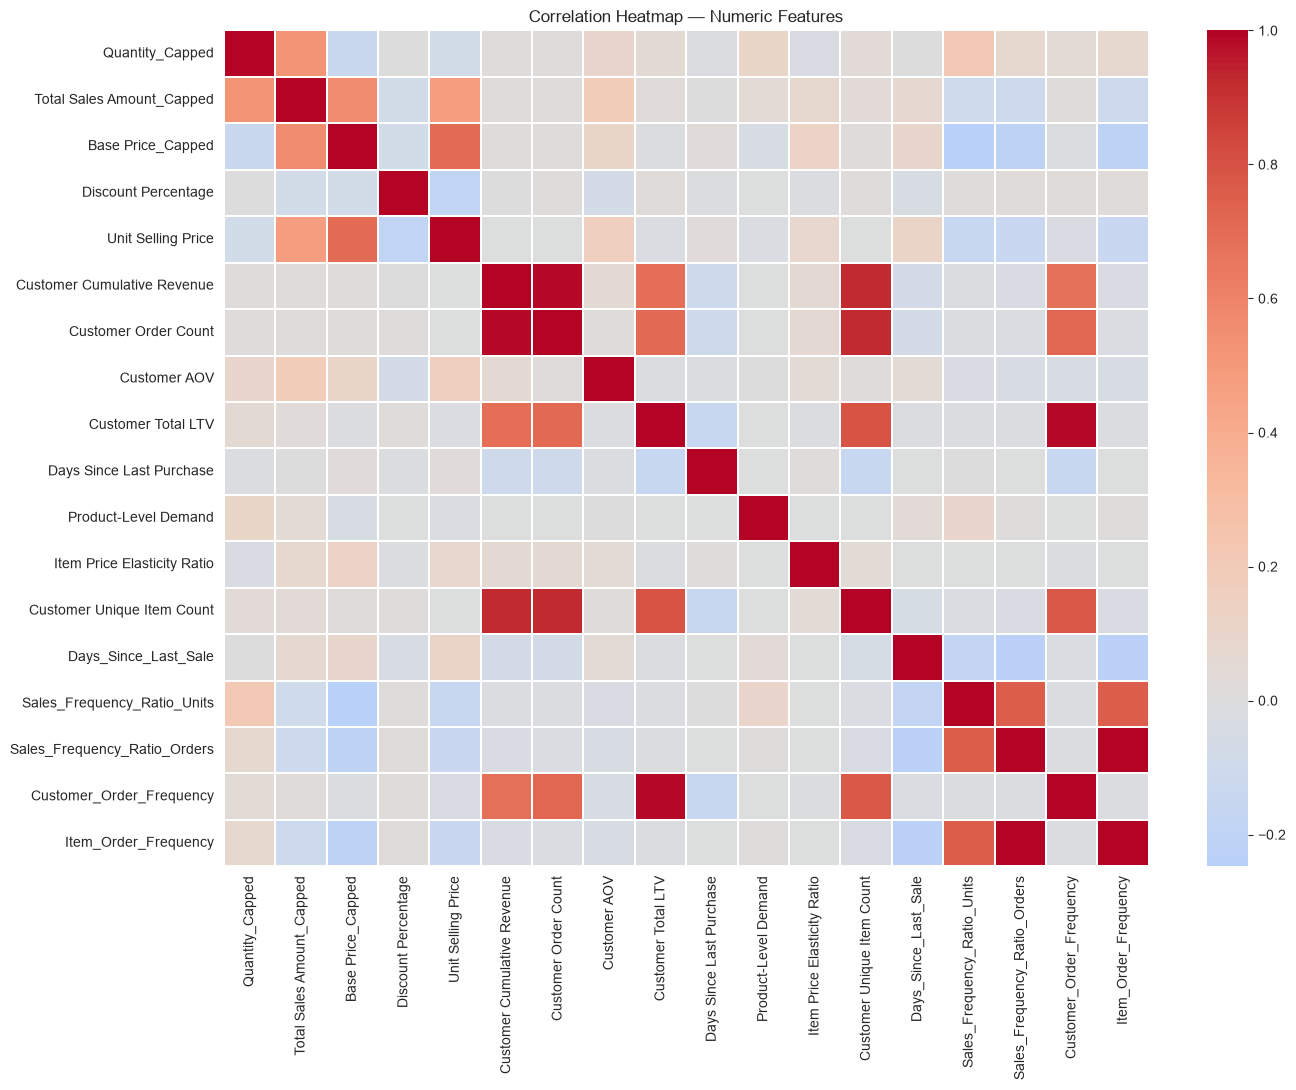

In [24]:
numeric_features = [
    'Quantity_Capped', 'Total Sales Amount_Capped', 'Base Price_Capped',
    'Discount Percentage', 'Unit Selling Price', 'Customer Cumulative Revenue',
    'Customer Order Count', 'Customer AOV', 'Customer Total LTV',
    'Days Since Last Purchase', 'Product-Level Demand', 'Item Price Elasticity Ratio',
    'Customer Unique Item Count', 'Days_Since_Last_Sale',
    'Sales_Frequency_Ratio_Units', 'Sales_Frequency_Ratio_Orders',
    'Customer_Order_Frequency', 'Item_Order_Frequency'
]

plt.figure(figsize=(14, 11))
corr = df[numeric_features].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()


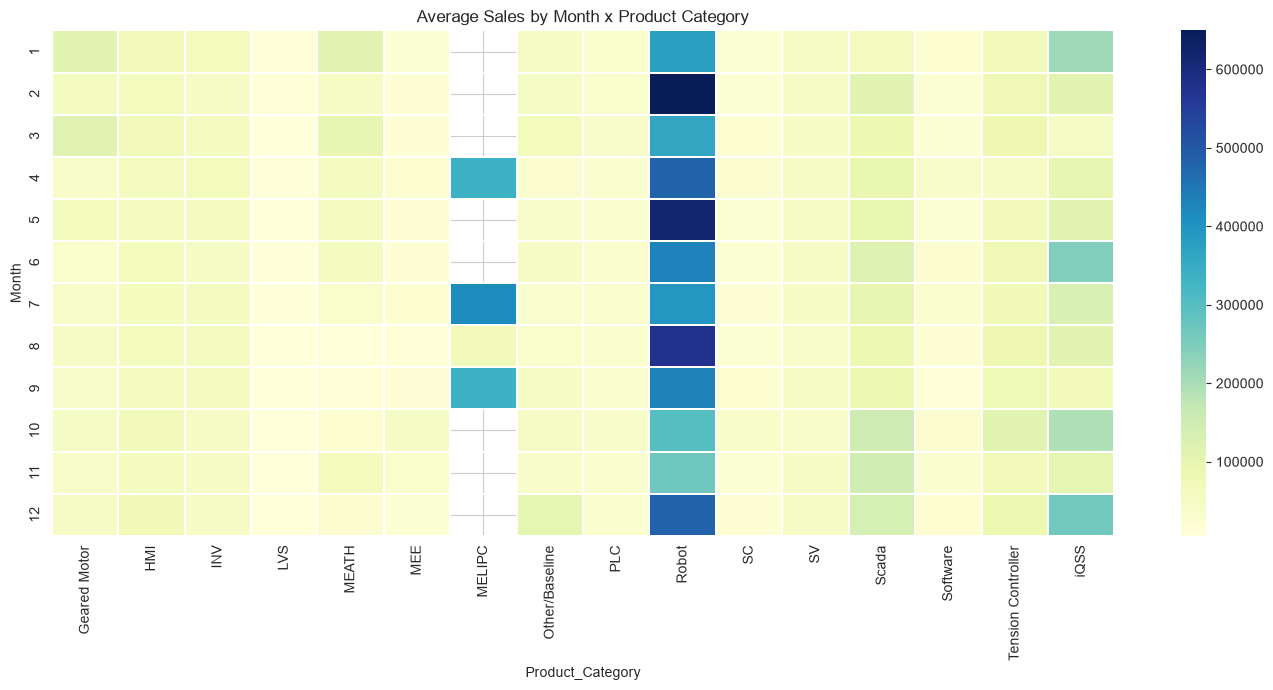

In [25]:
pivot = df.pivot_table(index='Month', columns='Product_Category',
                        values='Total Sales Amount', aggfunc='mean')

plt.figure(figsize=(14, 7))
sns.heatmap(pivot, cmap='YlGnBu', linewidths=0.3)
plt.title('Average Sales by Month x Product Category')
plt.tight_layout()
plt.show()


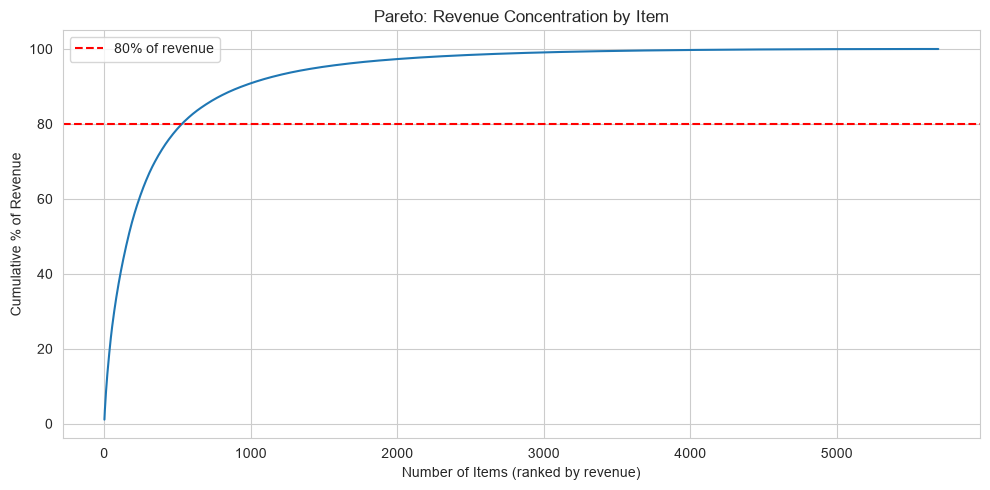

529 items (9.3% of 5693) drive 80% of revenue


In [26]:
item_rev = df.groupby('Item Internal Id')['Total Sales Amount'].sum().sort_values(ascending=False)
cum_pct = item_rev.cumsum() / item_rev.sum() * 100

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_pct) + 1), cum_pct.values)
plt.axhline(80, color='red', linestyle='--', label='80% of revenue')
plt.xlabel('Number of Items (ranked by revenue)')
plt.ylabel('Cumulative % of Revenue')
plt.title('Pareto: Revenue Concentration by Item')
plt.legend()
plt.tight_layout()
plt.show()

n_items_80pct = (cum_pct <= 80).sum()
print(f'{n_items_80pct} items ({n_items_80pct/len(item_rev)*100:.1f}% of {len(item_rev)}) drive 80% of revenue')


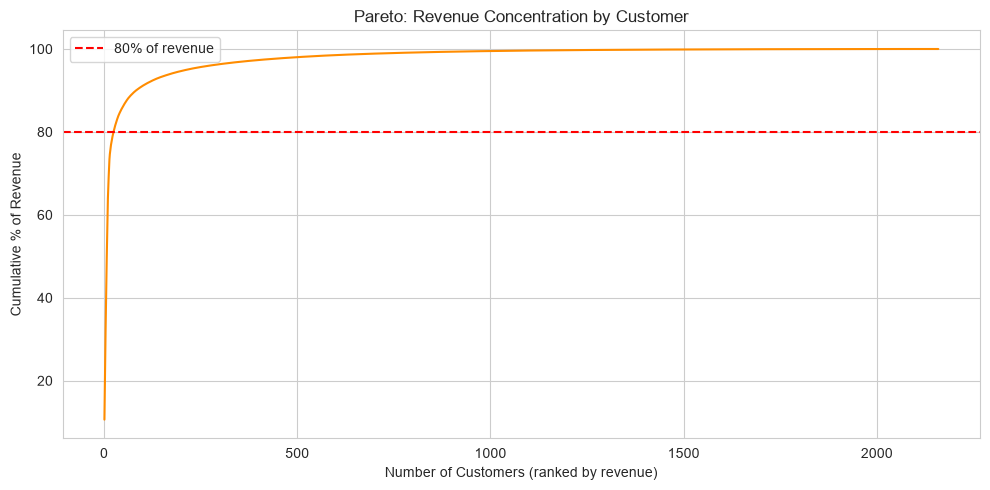

24 customers (1.1% of 2159) drive 80% of revenue


In [27]:
cust_rev = df.groupby('Customer Internal Id')['Total Sales Amount'].sum().sort_values(ascending=False)
cum_pct_c = cust_rev.cumsum() / cust_rev.sum() * 100

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_pct_c) + 1), cum_pct_c.values, color='darkorange')
plt.axhline(80, color='red', linestyle='--', label='80% of revenue')
plt.xlabel('Number of Customers (ranked by revenue)')
plt.ylabel('Cumulative % of Revenue')
plt.title('Pareto: Revenue Concentration by Customer')
plt.legend()
plt.tight_layout()
plt.show()

n_cust_80pct = (cum_pct_c <= 80).sum()
print(f'{n_cust_80pct} customers ({n_cust_80pct/len(cust_rev)*100:.1f}% of {len(cust_rev)}) drive 80% of revenue')


### Slow-moving / aging inventory
Aggregated to item level: for each item, the most recent `Days_Since_Last_Sale` and the total gross
value it has generated historically (a proxy for how much value/capital is tied to that item).

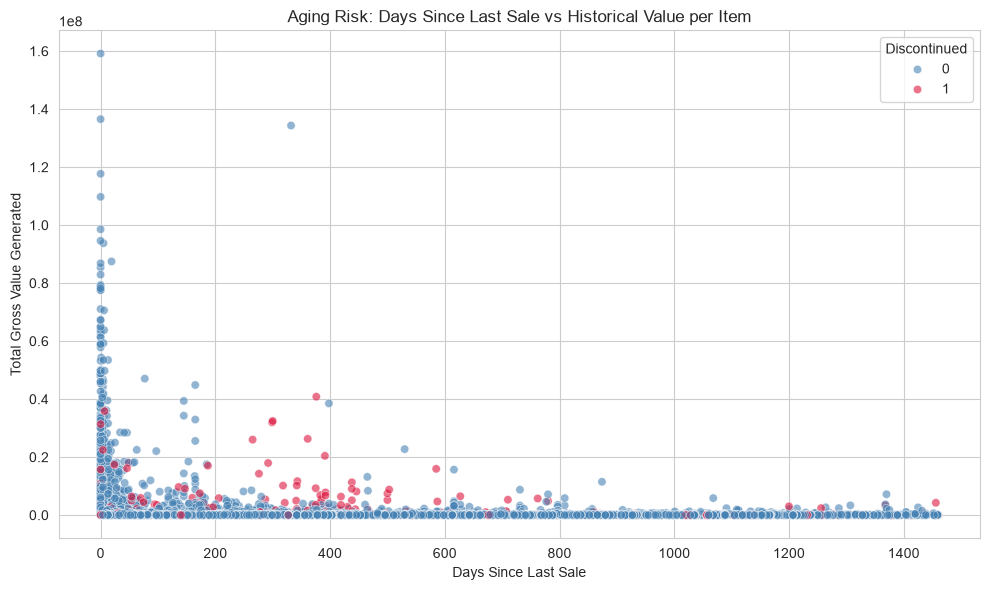

In [28]:
item_agg = df.groupby('Item Internal Id').agg(
    Days_Since_Last_Sale=('Days_Since_Last_Sale', 'min'),
    Total_Gross_Value=('Total Gross Value', 'sum'),
    Product_Category=('Product_Category', 'first'),
    Discontinued=('Production Status_Discontinue', 'max')
).reset_index()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=item_agg, x='Days_Since_Last_Sale', y='Total_Gross_Value',
                 hue='Discontinued', alpha=0.6, palette={0: 'steelblue', 1: 'crimson'})
plt.title('Aging Risk: Days Since Last Sale vs Historical Value per Item')
plt.xlabel('Days Since Last Sale')
plt.ylabel('Total Gross Value Generated')
plt.tight_layout()
plt.show()


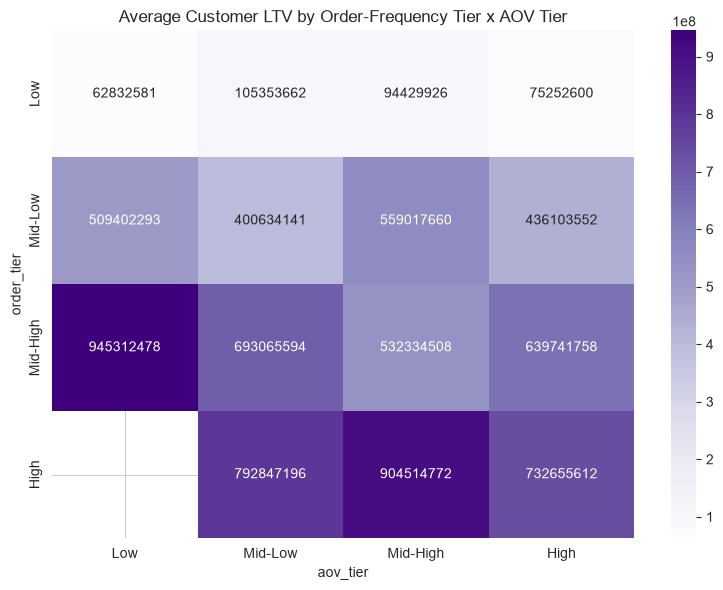

In [29]:
cust_tier = pd.qcut(df['Customer Order Count'], 4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'], duplicates='drop')
aov_tier = pd.qcut(df['Customer AOV'], 4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'], duplicates='drop')

ltv_pivot = df.assign(order_tier=cust_tier, aov_tier=aov_tier).pivot_table(
    index='order_tier', columns='aov_tier', values='Customer Total LTV', aggfunc='mean')

plt.figure(figsize=(8, 6))
sns.heatmap(ltv_pivot, annot=True, fmt='.0f', cmap='Purples')
plt.title('Average Customer LTV by Order-Frequency Tier x AOV Tier')
plt.tight_layout()
plt.show()


## 6. Financial Risk from Aging Inventory

Flags items that (a) haven't sold in a long time relative to the dataset window and
(b) are marked Discontinued / To Be Advised — these are the items most likely tying up
capital in stock that may never sell. Adjust the `days_threshold` if you have a specific
"5 years" business rule in mind, or merge in a real item-age field if you have one.

Using Days_Since_Last_Sale >= 1088 days as the "aging" cutoff
72 items flagged as aging + discontinued
Historical value tied to these items: 16,948,600 (0.1% of all-time gross value)


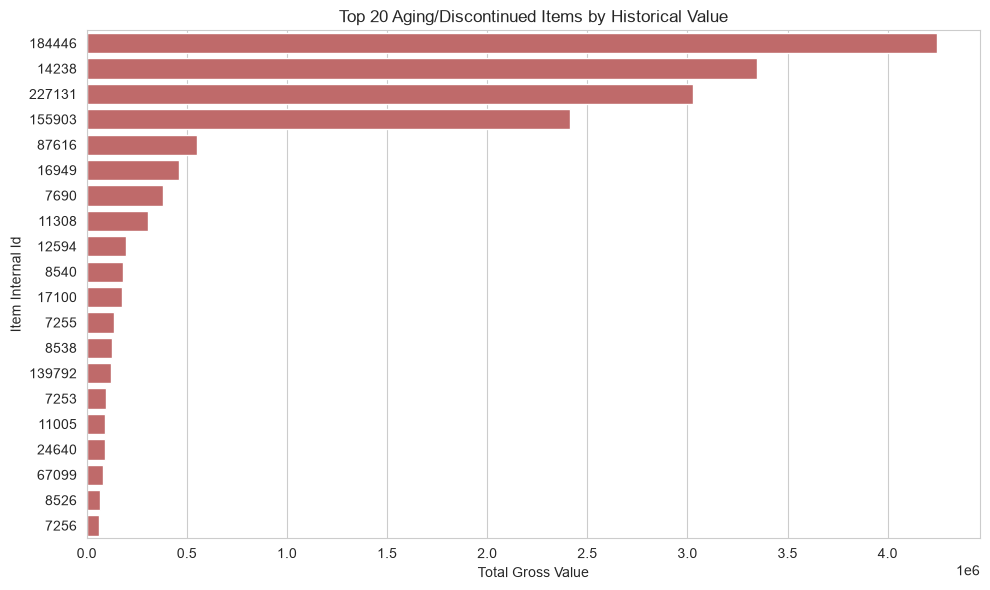

,Item Internal Id,Days_Since_Last_Sale,Total_Gross_Value,Product_Category,Discontinued
4583,184446,1456,4248708.0,Robot,1
1388,14238,1368,3346034.0,Robot,1
4972,227131,1200,3030136.0,Robot,1
4258,155903,1256,2412104.0,iQSS,1
3321,87616,1435,552718.0,Robot,1
1678,16949,1088,458376.0,Software,1
133,7690,1277,381078.0,HMI,1
1218,11308,1130,307776.0,PLC,1
1374,12594,1204,196784.0,INV,1
409,8540,1354,180015.0,INV,1


In [30]:
days_threshold = item_agg['Days_Since_Last_Sale'].quantile(0.90)  # top 10% longest since last sale
print(f'Using Days_Since_Last_Sale >= {days_threshold:.0f} days as the "aging" cutoff')

at_risk = item_agg[
    (item_agg['Days_Since_Last_Sale'] >= days_threshold) &
    (item_agg['Discontinued'] == 1)
].sort_values('Total_Gross_Value', ascending=False)

total_value_at_risk = at_risk['Total_Gross_Value'].sum()
pct_of_all_value = total_value_at_risk / item_agg['Total_Gross_Value'].sum() * 100

print(f'{len(at_risk)} items flagged as aging + discontinued')
print(f'Historical value tied to these items: {total_value_at_risk:,.0f} ({pct_of_all_value:.1f}% of all-time gross value)')

plt.figure(figsize=(10, 6))
top20 = at_risk.head(20)
sns.barplot(data=top20, y='Item Internal Id', x='Total_Gross_Value', orient='h',
            order=top20['Item Internal Id'].astype(str), color='indianred')
plt.title('Top 20 Aging/Discontinued Items by Historical Value')
plt.xlabel('Total Gross Value')
plt.tight_layout()
plt.show()

at_risk.head(20)
